[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jseborga/recursos-ia/blob/main/notebooks/02_fisica_clasica.ipynb)

# Física clásica con verificación incorporada

Seis ejemplos de Física Básica I y II. Cada uno sigue la misma estructura del taller:

1. **Modelo** con su ecuación.
2. **Cálculo numérico** con Python.
3. **Control**: se compara con una solución exacta o con una ley de conservación. Si no coincide, el cuaderno se detiene con `✘`.
4. **Pregunta para el aula** y **prompt** para pedirle a la IA una variante.

*Entorno de ejecución → Ejecutar todo* tarda menos de un minuto en el plan gratuito.

| # | Ejemplo | Control |
|---|---|---|
| 1 | Péndulo simple de amplitud grande | Período exacto con integral elíptica |
| 2 | Caída con resistencia del aire | Solución analítica con tanh |
| 3 | Oscilador forzado y resonancia | Amplitud estacionaria analítica |
| 4 | Carga de un capacitor (RC) | Balance de energía: la resistencia disipa ½CV² |
| 5 | Choques en una dimensión | Conservación del momento y de la energía |
| 6 | Laboratorio: g con un péndulo | Ajuste con incertidumbre y χ² |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, trapezoid
from scipy.special import ellipk
from scipy.optimize import curve_fit, brentq

plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": .3})
G_LAPAZ = 9.773   # m/s², estimación con la fórmula de gravedad normal (lat. 16,5° S, 3640 m)
G_STD = 9.80665   # m/s², gravedad estándar

def verificar(condicion, mensaje):
    """Detiene el cuaderno si un control falla; si pasa, lo informa."""
    if not condicion:
        raise AssertionError("✘ " + mensaje)
    print("✔", mensaje)

## 1 · Péndulo simple: ¿hasta dónde vale $T = 2\pi\sqrt{L/g}$?

$$\ddot\theta = -\frac{g}{L}\sin\theta \qquad\qquad T_{\text{exacto}} = 4\sqrt{\frac{L}{g}}\;K\!\left(\sin^2\tfrac{\theta_0}{2}\right)$$

$K(m)$ es la integral elíptica completa de primera especie (`scipy.special.ellipk` usa el parámetro $m = k^2$). El período numérico se mide como cuatro veces el tiempo que tarda el péndulo, soltado desde $\theta_0$, en pasar por la vertical.

✔ θ0 =  10°: numérico 2.013694 s = exacto 2.013694 s  (T/T0 = 1.0019)
✔ θ0 =  45°: numérico 2.090201 s = exacto 2.090201 s  (T/T0 = 1.0400)
✔ θ0 =  90°: numérico 2.372320 s = exacto 2.372320 s  (T/T0 = 1.1803)
✔ θ0 = 150°: numérico 3.541784 s = exacto 3.541784 s  (T/T0 = 1.7622)

La fórmula de ángulo pequeño se equivoca en más de 1 % a partir de θ0 ≈ 22.8°


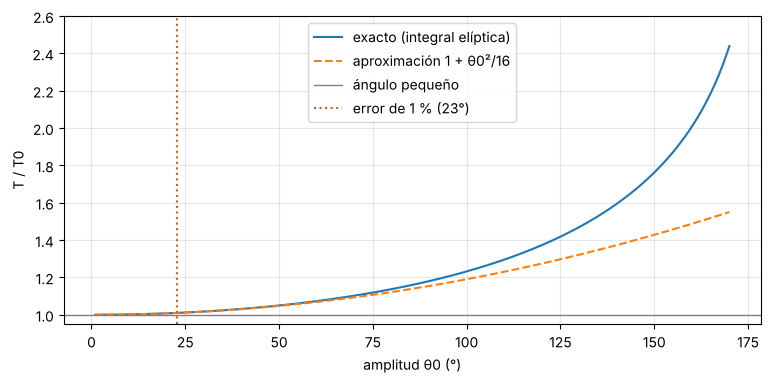

In [2]:
L, g = 1.0, G_LAPAZ        # ← cambie la longitud (m)
T0 = 2*np.pi*np.sqrt(L/g)

def periodo_numerico(theta0):
    f = lambda t, s: [s[1], -g/L*np.sin(s[0])]
    vertical = lambda t, s: s[0]
    vertical.terminal, vertical.direction = True, -1
    sol = solve_ivp(f, (0, 10*T0), [theta0, 0], events=vertical, rtol=1e-11, atol=1e-12)
    return 4*sol.t_events[0][0]

def periodo_exacto(theta0):
    return 4*np.sqrt(L/g)*ellipk(np.sin(theta0/2)**2)

for grados in (10, 45, 90, 150):
    th = np.radians(grados)
    Tn, Te = periodo_numerico(th), periodo_exacto(th)
    verificar(abs(Tn - Te)/Te < 1e-7, f"θ0 = {grados:>3}°: numérico {Tn:.6f} s = exacto {Te:.6f} s  (T/T0 = {Te/T0:.4f})")

lim1 = brentq(lambda d: periodo_exacto(np.radians(d))/T0 - 1.01, 1, 90)
print(f"\nLa fórmula de ángulo pequeño se equivoca en más de 1 % a partir de θ0 ≈ {lim1:.1f}°")

ang = np.linspace(1, 170, 300)
plt.plot(ang, [periodo_exacto(np.radians(a))/T0 for a in ang], label="exacto (integral elíptica)")
plt.plot(ang, 1 + np.radians(ang)**2/16, "--", label="aproximación 1 + θ0²/16")
plt.axhline(1, color="gray", lw=1, label="ángulo pequeño")
plt.axvline(lim1, color="#c4661c", ls=":", label=f"error de 1 % ({lim1:.0f}°)")
plt.xlabel("amplitud θ0 (°)"); plt.ylabel("T / T0"); plt.ylim(0.95, 2.6); plt.legend(); plt.show()

**Pregunta para el aula:** en el laboratorio se suelta el péndulo a 20°. ¿Qué error sistemático introduce usar $T = 2\pi\sqrt{L/g}$ al calcular $g$? (Pista: $g \propto 1/T^2$, así que el error relativo en $g$ es el doble que en $T$.)

**Prompt para variar con IA:** «Modifica esta celda para un péndulo físico (una barra de longitud L que oscila desde un extremo) y agrega el control equivalente con la integral elíptica.»

## 2 · Caída con resistencia del aire: velocidad terminal

$$m\,\dot v = m g - c\,v^2, \qquad c = \tfrac12\rho\,C_d\,A \qquad\Rightarrow\qquad v(t) = v_t \tanh\!\left(\frac{g\,t}{v_t}\right),\quad v_t = \sqrt{\frac{m g}{c}}$$

Paracaidista en posición de caída libre. $C_d \approx 1{,}0$ y $A \approx 0{,}7\ \text{m}^2$ son valores ilustrativos: cambie ambos por los de su problema.

✔ La Paz (ρ ≈ 0,85 kg/m³): numérico = analítico (error máx. 1.9e-10); v_t = 51.3 m/s = 185 km/h
✔ Nivel del mar (ρ = 1,225 kg/m³): numérico = analítico (error máx. 1.7e-10); v_t = 42.8 m/s = 154 km/h


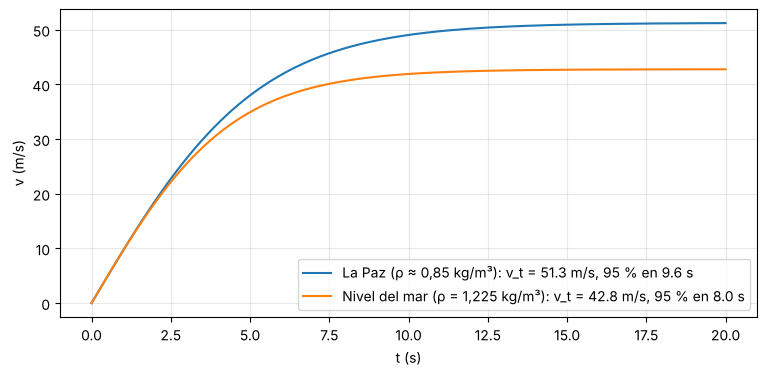

In [3]:
m, Cd, A = 80.0, 1.0, 0.7      # ← kg, adimensional, m² (valores ilustrativos)
casos = {"La Paz (ρ ≈ 0,85 kg/m³)": (0.85, G_LAPAZ), "Nivel del mar (ρ = 1,225 kg/m³)": (1.225, G_STD)}

t = np.linspace(0, 20, 400)
for nombre, (rho, g) in casos.items():
    c = 0.5*rho*Cd*A
    vt = np.sqrt(m*g/c)
    sol = solve_ivp(lambda t, v: [g - c/m*v[0]**2], (0, 20), [0], t_eval=t, rtol=1e-10, atol=1e-12)
    v_exacta = vt*np.tanh(g*t/vt)
    err = np.max(np.abs(sol.y[0] - v_exacta))/vt
    verificar(err < 1e-7, f"{nombre}: numérico = analítico (error máx. {err:.1e}); v_t = {vt:.1f} m/s = {vt*3.6:.0f} km/h")
    t95 = vt/g*np.arctanh(0.95)
    plt.plot(t, sol.y[0], label=f"{nombre}: v_t = {vt:.1f} m/s, 95 % en {t95:.1f} s")
plt.xlabel("t (s)"); plt.ylabel("v (m/s)"); plt.legend(); plt.show()

**Pregunta para el aula:** ¿por qué la velocidad terminal en La Paz es mayor, y en qué proporción? (Compare $\sqrt{1{,}225/0{,}85}$ con el cociente de las dos $v_t$.)

**Prompt para variar con IA:** «Agrega la apertura del paracaídas en t = 15 s (C_d·A pasa de 0,7 a 25 m²) y calcula la desaceleración máxima en múltiplos de g.»

## 3 · Oscilador amortiguado y forzado: resonancia

$$\ddot x + 2\beta\,\dot x + \omega_0^2 x = \frac{F_0}{m}\cos\omega t \qquad\Rightarrow\qquad A(\omega) = \frac{F_0/m}{\sqrt{(\omega_0^2-\omega^2)^2 + 4\beta^2\omega^2}}$$

La amplitud numérica se mide en el régimen estacionario: se integra hasta que el transitorio $\propto e^{-\beta t}$ se apaga y se toma el máximo de $|x|$ en los últimos períodos.

✔ β = 0.5: amplitud numérica = analítica en 5 frecuencias (error máx. 0.00 %)


✔ β = 1.0: amplitud numérica = analítica en 5 frecuencias (error máx. 0.00 %)


✔ β = 2.0: amplitud numérica = analítica en 5 frecuencias (error máx. 0.00 %)


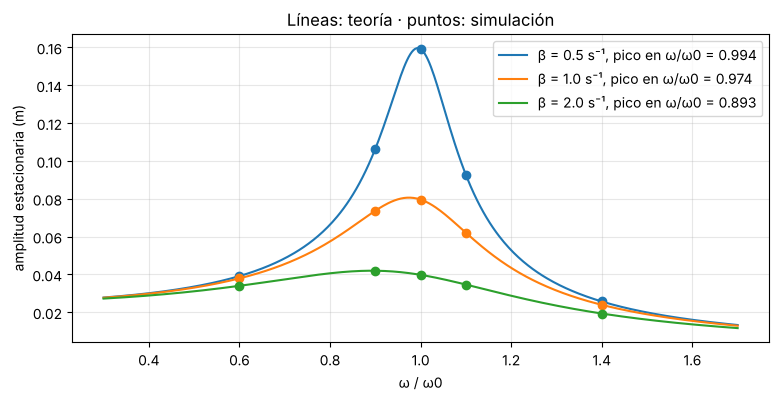

In [4]:
w0, F0m = 2*np.pi, 1.0                       # ω0 = 2π rad/s (1 Hz), F0/m = 1 N/kg
A_teo = lambda w, b: F0m/np.sqrt((w0**2 - w**2)**2 + 4*b**2*w**2)

def A_num(w, b):
    f = lambda t, s: [s[1], F0m*np.cos(w*t) - 2*b*s[1] - w0**2*s[0]]
    t_trans = 30/b                               # e^(-30) ≈ 1e-13: transitorio apagado
    T = 2*np.pi/w
    t = np.linspace(t_trans, t_trans + 5*T, 4000)
    sol = solve_ivp(f, (0, t[-1]), [0, 0], t_eval=t, rtol=1e-10, atol=1e-12)
    return np.max(np.abs(sol.y[0]))

ws = np.linspace(0.3*w0, 1.7*w0, 400)
for b in (0.5, 1.0, 2.0):
    pts = np.array([0.6, 0.9, 1.0, 1.1, 1.4])*w0
    num = [A_num(w, b) for w in pts]
    err = max(abs(n - A_teo(w, b))/A_teo(w, b) for n, w in zip(num, pts))
    verificar(err < 2e-3, f"β = {b}: amplitud numérica = analítica en 5 frecuencias (error máx. {err*100:.2f} %)")
    wr = np.sqrt(w0**2 - 2*b**2)
    line, = plt.plot(ws/w0, A_teo(ws, b), label=f"β = {b} s⁻¹, pico en ω/ω0 = {wr/w0:.3f}")
    plt.plot(pts/w0, num, "o", color=line.get_color())
plt.xlabel("ω / ω0"); plt.ylabel("amplitud estacionaria (m)"); plt.title("Líneas: teoría · puntos: simulación"); plt.legend(); plt.show()

**Pregunta para el aula:** ¿por qué el pico de resonancia no está exactamente en $\omega_0$? ¿Qué pasa con el pico si $\beta > \omega_0/\sqrt2$?

**Prompt para variar con IA:** «Agrega la gráfica de la fase entre la fuerza y la respuesta y verifica que vale −90° en ω = ω0 para cualquier β.»

## 4 · Carga de un capacitor: ¿a dónde va la energía?

$$R\,\dot q + \frac{q}{C} = V \qquad\Rightarrow\qquad q(t) = CV\left(1 - e^{-t/RC}\right)$$

Resultado poco intuitivo: la batería entrega $CV^2$, el capacitor almacena $\tfrac12 CV^2$ y la resistencia disipa **la otra mitad, sea cual sea $R$**. El control lo comprueba integrando $I^2R$ numéricamente para tres resistencias.

✔ R = 10 Ω: q(t) numérica = analítica
✔ R = 10 Ω: energía disipada 7.2000 mJ = ½CV² = 7.2000 mJ  (τ = 0.001 s)
✔ R = 1000 Ω: q(t) numérica = analítica
✔ R = 1000 Ω: energía disipada 7.2000 mJ = ½CV² = 7.2000 mJ  (τ = 0.1 s)
✔ R = 100000 Ω: q(t) numérica = analítica
✔ R = 100000 Ω: energía disipada 7.2000 mJ = ½CV² = 7.2000 mJ  (τ = 10 s)


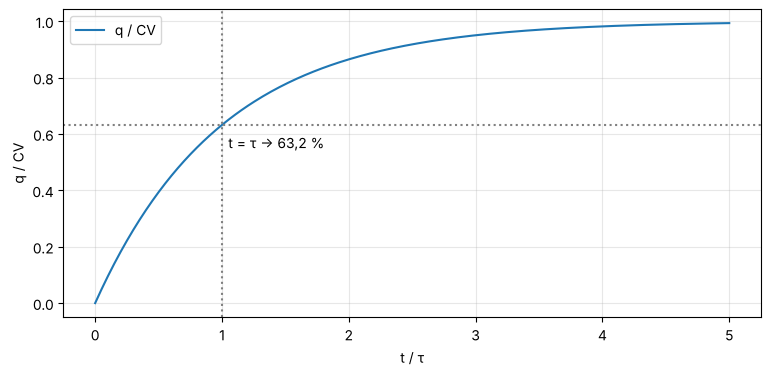

In [5]:
C, V = 100e-6, 12.0                     # 100 µF, 12 V
for R in (10, 1e3, 1e5):                 # Ω
    tau = R*C
    t = np.linspace(0, 15*tau, 20001)
    sol = solve_ivp(lambda t, q: [(V - q[0]/C)/R], (0, t[-1]), [0], t_eval=t, rtol=1e-11, atol=1e-15)
    q = sol.y[0]
    verificar(np.max(np.abs(q - C*V*(1 - np.exp(-t/tau))))/(C*V) < 1e-7, f"R = {R:g} Ω: q(t) numérica = analítica")
    I = (V - q/C)/R
    E_R = trapezoid(I**2*R, t)
    verificar(abs(E_R - 0.5*C*V**2)/(0.5*C*V**2) < 1e-4,
              f"R = {R:g} Ω: energía disipada {E_R*1e3:.4f} mJ = ½CV² = {0.5*C*V**2*1e3:.4f} mJ  (τ = {tau:g} s)")

tau = 1e3*C; t = np.linspace(0, 5*tau, 300)
plt.plot(t/tau, 1 - np.exp(-t/tau), label="q / CV")
plt.axvline(1, ls=":", color="gray"); plt.axhline(1 - np.exp(-1), ls=":", color="gray")
plt.text(1.05, 0.55, "t = τ → 63,2 %"); plt.xlabel("t / τ"); plt.ylabel("q / CV"); plt.legend(); plt.show()

**Pregunta para el aula:** si la mitad de la energía siempre se pierde, ¿cómo se podría cargar un capacitor con menos pérdidas? (Pista: cargarlo en varios escalones de voltaje.)

**Prompt para variar con IA:** «Simula la carga en N escalones de V/N cada uno y verifica que la energía disipada total es ½CV²/N.»

## 5 · Choques en una dimensión

Con coeficiente de restitución $e$ ($e = 1$ elástico, $e = 0$ perfectamente inelástico):

$$v_1 = \frac{m_1u_1 + m_2u_2 + m_2e(u_2-u_1)}{m_1+m_2},\qquad v_2 = \frac{m_1u_1 + m_2u_2 + m_1e(u_1-u_2)}{m_1+m_2}$$

Los controles prueban 1000 choques al azar: el momento se conserva siempre; la energía cinética, solo si $e = 1$.

✔ 1000 choques al azar: momento conservado (error máx. 2.8e-14 kg·m/s)
✔ velocidad relativa de salida = −e · velocidad relativa de entrada
✔ con e = 1 la energía cinética se conserva


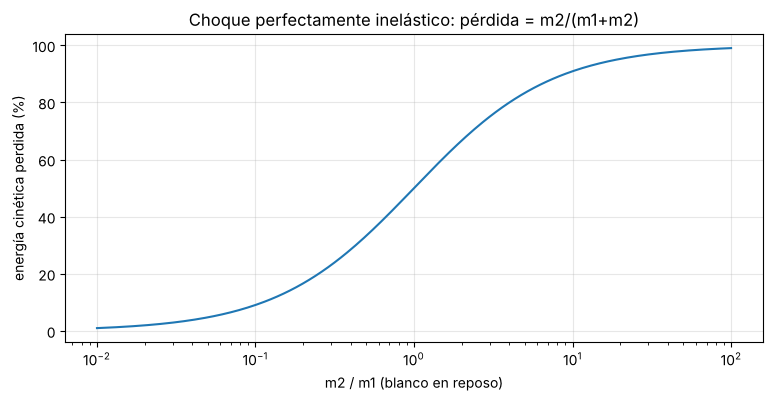

In [6]:
def choque(m1, m2, u1, u2, e):
    P = m1*u1 + m2*u2
    return (P + m2*e*(u2 - u1))/(m1 + m2), (P + m1*e*(u1 - u2))/(m1 + m2)

rng = np.random.default_rng(2026)
m1, m2 = rng.uniform(0.1, 10, (2, 1000)); u1, u2 = rng.uniform(-10, 10, (2, 1000)); e = rng.uniform(0, 1, 1000)
v1, v2 = choque(m1, m2, u1, u2, e)
p_err = np.max(np.abs((m1*v1 + m2*v2) - (m1*u1 + m2*u2)))
verificar(p_err < 1e-10, f"1000 choques al azar: momento conservado (error máx. {p_err:.1e} kg·m/s)")
verificar(np.allclose((v2 - v1), -e*(u2 - u1)), "velocidad relativa de salida = −e · velocidad relativa de entrada")
v1, v2 = choque(m1, m2, u1, u2, 1.0)
K0, K1 = 0.5*(m1*u1**2 + m2*u2**2), 0.5*(m1*v1**2 + m2*v2**2)
verificar(np.allclose(K0, K1), "con e = 1 la energía cinética se conserva")

r = np.logspace(-2, 2, 300)                      # m2/m1, blanco en reposo, e = 0
plt.semilogx(r, r/(1 + r)*100)
plt.xlabel("m2 / m1 (blanco en reposo)"); plt.ylabel("energía cinética perdida (%)")
plt.title("Choque perfectamente inelástico: pérdida = m2/(m1+m2)"); plt.show()

**Pregunta para el aula:** en un péndulo balístico, ¿por qué no se puede usar conservación de energía durante el impacto, pero sí después?

**Prompt para variar con IA:** «Generaliza la función a choques en dos dimensiones con parámetro de impacto b y verifica la conservación del momento en x y en y.»

## 6 · Laboratorio: medir $g$ con un péndulo y ajustar con incertidumbres

$$T^2 = \frac{4\pi^2}{g}\,L \qquad\Rightarrow\qquad \text{recta de pendiente } 4\pi^2/g$$

> **Los datos de abajo son sintéticos**: se generaron con $g = 9{,}773\ \text{m/s}^2$ y ruido aleatorio de $\sigma_T = 0{,}01\ \text{s}$, para comprobar que el método recupera el valor conocido. Reemplácelos por las mediciones de su grupo.

El control exige que el valor conocido caiga dentro de 3 incertidumbres estándar del ajuste y que $\chi^2_\nu$ sea razonable (cerca de 1).

g = 9.695 ± 0.042 m/s²   (χ²/ν = 1.65)
✔ el valor usado para generar los datos (9.773) está dentro de 3σ
✔ χ²/ν compatible con las incertidumbres declaradas


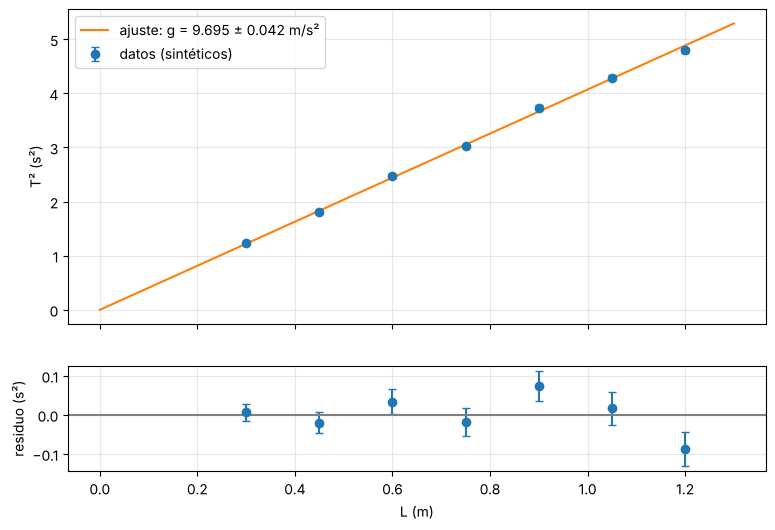

In [7]:
# ← Reemplace estas tres líneas por sus mediciones (L en m, T en s, incertidumbre de T en s)
rng = np.random.default_rng(16102026)
L_med = np.array([0.30, 0.45, 0.60, 0.75, 0.90, 1.05, 1.20])
sT = np.full_like(L_med, 0.01)
T_med = 2*np.pi*np.sqrt(L_med/G_LAPAZ) + rng.normal(0, sT)

y, sy = T_med**2, 2*T_med*sT                    # propagación: σ(T²) = 2T·σ_T
modelo = lambda L, a: a*L
(a,), cov = curve_fit(modelo, L_med, y, sigma=sy, absolute_sigma=True)
ua = np.sqrt(cov[0, 0])
g_fit, ug = 4*np.pi**2/a, 4*np.pi**2/a**2*ua
chi2nu = np.sum(((y - modelo(L_med, a))/sy)**2)/(len(L_med) - 1)

print(f"g = {g_fit:.3f} ± {ug:.3f} m/s²   (χ²/ν = {chi2nu:.2f})")
verificar(abs(g_fit - G_LAPAZ) < 3*ug, f"el valor usado para generar los datos ({G_LAPAZ}) está dentro de 3σ")
verificar(0.2 < chi2nu < 3, "χ²/ν compatible con las incertidumbres declaradas")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax1.errorbar(L_med, y, yerr=sy, fmt="o", capsize=3, label="datos (sintéticos)")
Ls = np.linspace(0, 1.3, 50); ax1.plot(Ls, modelo(Ls, a), label=f"ajuste: g = {g_fit:.3f} ± {ug:.3f} m/s²")
ax1.set_ylabel("T² (s²)"); ax1.legend()
ax2.errorbar(L_med, y - modelo(L_med, a), yerr=sy, fmt="o", capsize=3); ax2.axhline(0, color="gray")
ax2.set_xlabel("L (m)"); ax2.set_ylabel("residuo (s²)"); plt.show()

**Pregunta para el aula:** si los residuos muestran una curva en lugar de puntos al azar, ¿qué efecto físico del ejemplo 1 podría estar causándolo?

**Prompt para variar con IA:** «Agrega un parámetro de ordenada al origen al ajuste (T² = aL + b) y explica qué error experimental revelaría un b distinto de cero.»

---
*Material del Módulo 8, «El auxiliar aumentado». Licencia CC BY 4.0.*